# Creating a Growing Season Indicator of Water Stress for Slovakia

Data: E-HYPE
RCP 4.5
2011-2040

# Source data and model chain
Swedish Meteorological and Hydrological Institute (SMHI) E-HYPE model, forced by one EURO-CORDEX regional climate model run (CCLM4-8-17) nested in one global model EC-EARTH, ensemble member r12i1p1 under RCP 4.5.

Climate-model output bias-adjusted to EFAS-Meteo reference data from period 1990-2018 before it drove the hydrological model.

# Summary and Design Decisions
This project demonstrates a 5-level, categorical indiator of drought stress through 2040 during the Slovak growing season (months April through September inclusive) using the data above. 

The indicator is derived from a monthly climatology of change, or the average % change of each month over the period. The categories ranges 1-5, from least to greatest % change to potential aridity.

Two data series are included.
Modelled runoff: A proxy for water availability. The data are in % relative change.

PET/P ratio: Potential Evapotranspiration to precipitation. **Note that this is the inverse of the United Nations Environmental Programme's aridity index, so the values are sign-flipped here** (i.e. a positive value means increase in drought).

# Caveats
Data used here are simple ratios and lack full context (i.e. a 10% change may or may not be a big difference depending on the baseline)

All negative values here arerunoff or PET/P increases, which are collapsed into the single "very low" bin for the indicator. This could represent increased risk of flood which I will add as an acute hazard coincident with these metrics. This will make use of the CLIMADA Python library in a separate notebook.

I want to add a baseline layer next, probably of rainfall. I am currently exploring which dataset is most suitable for this.

The data are 5km gridded, I want to also cross-reference against catchment basin polygon data if it's available and compare the results.


# Future Work Roadmap
1. Add an exposure layer
2. Add a flood hazard layer
3. Add catchment basin data
4. Explore 2041-2070 timeframe

**IMPORTS AND PARAMETERS**

In [1]:
import calendar
import json
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import shapely
from pyproj import CRS, Transformer
from scipy.spatial import cKDTree
from IPython.display import display

import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap, TwoSlopeNorm

# ---------------------PATHS---------------------
DATA_DIR      = Path("../data")
HYDRO_DIR     = DATA_DIR / "hydrology"
OUT_DIR       = DATA_DIR / "processed"
BOUNDARY_FILE = DATA_DIR / "boundary" / "slovakia_epsg3035.gpkg"   # NEW: cached country boundary
EXP_FILE      = DATA_DIR / "slovakia_exp.hdf5"                     # placeholder until new exposure added
ZIP_PATH      = DATA_DIR / "slovakia_hydrology_indicators.zip"
OUT_DIR.mkdir(parents=True, exist_ok=True)


#---------------------PARAMETERS---------------------
ANALYSIS_CRS      = "EPSG:3035"                                    # ETRS89-LAEA equal-area projection.
CELL_SIZE_M       = 5000                                           # 5km grid for gridded data  
GRID_TOL_M        = 50                                             # Grid tolerance (deviation from perfect grid)

# Months chosen
GROWING_MONTHS    = [4, 5, 6, 7, 8, 9]                             # April to September

# Runoff is mean percent change and sign-flipped, becomes runoff loss (higher number = higher loss) runoff_loss_pct = -(mean % change)
# Aridity is mean percent change of PET/P ratio, per data.
RUNOFF_LOSS_EDGES = [0, 10, 20, 30]                                # class boundaries (lower) for modelled runoff % delta.
ARIDITY_EDGES     = [0, 10, 20, 40]                                # class boundaries (lower) for PET/P % delta.
CLASS_NAMES = {1: "very low", 2: "low", 3: "moderate", 4: "high", 5: "very high"}

# A bounding box for clipping to Slovakia
LAT_MIN, LAT_MAX = 47.7, 49.6
LON_MIN, LON_MAX = 16.8, 22.6


In [2]:
#Prints every library's version number if installed to record those used for analysis, or alert if they are not installed. Any other error types will still come through.

import importlib.metadata as md

for pkg in ["climada", "xarray", "geopandas", "shapely", "pyproj", "numpy", "scipy", "pandas", "matplotlib"]:
    try:
        print(f"{pkg:12s}{md.version(pkg)}")
    except md.PackageNotFoundError:
        print(f"{pkg:12s}not installed")

climada     6.1.0
xarray      2025.6.1
geopandas   1.1.2
shapely     2.1.2
pyproj      3.7.2
numpy       1.26.4
scipy       1.15.2
pandas      2.1.4
matplotlib  3.10.8


**Data retrieval**

In [3]:
CDS_DATASET = "sis-hydrology-variables-derived-projections"
CDS_REQUEST = {
    "product_type": "climate_impact_indicators",
    "variable": ["mean_runoff", "aridity_potential"],
    "variable_type": "relative_change_from_reference_period",
    "time_aggregation": "monthly_mean",
    "experiment": ["rcp_4_5"],
    "hydrological_model": ["e_hypecatch_m00", "e_hypegrid"],
    "rcm": "cclm4_8_17",
    "gcm": "ec_earth",
    "ensemble_member": ["r12i1p1"],
    "period": ["2011_2040"],
}

import os                                                    
from pathlib import Path

def have_cds_credentials():                                  
    """True if cdsapi can find a key outside this repo."""
    env_ok = "CDSAPI_URL" in os.environ and "CDSAPI_KEY" in os.environ
    rc = Path(os.environ.get("CDSAPI_RC", "~/.cdsapirc")).expanduser()
    return env_ok or rc.exists()

have_nc = any(HYDRO_DIR.glob("*.nc"))

if not have_nc and not ZIP_PATH.exists():
    import cdsapi
    if not have_cds_credentials():                           
        raise RuntimeError(
            "No CDS credentials found. Create ~/.cdsapirc or set CDSAPI_URL and CDSAPI_KEY "
            "(see README), and accept the dataset licence on the CDS website."
        )
    ZIP_PATH.parent.mkdir(parents=True, exist_ok=True)
    cdsapi.Client().retrieve(CDS_DATASET, CDS_REQUEST).download(str(ZIP_PATH))

have_nc = any(HYDRO_DIR.glob("*.nc"))

if not have_nc and not ZIP_PATH.exists():                           # downloads only if not already present
    ZIP_PATH.parent.mkdir(parents=True, exist_ok=True)
    os.environ["CDSAPI_RC"] = str(Path("../.cdsapirc").resolve())
    cdsapi.Client().retrieve(CDS_DATASET, CDS_REQUEST).download(str(ZIP_PATH))

if not have_nc:                                                     # extract only if not already extracted
    HYDRO_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(HYDRO_DIR)

print("unzipped files found:")
for i, f in enumerate(sorted(HYDRO_DIR.glob("*.nc")), start=1):
    print(f"{i}. {f.name}")

unzipped files found:
1. aridpot_ymonmean_rel_E-HYPEcatch00-EUR-11_ICHEC-EC-EARTH_rcp45_r12i1p1_CLMcom-CCLM4-8-17-v1_2011-2040_1971-2000_catch_v1.nc
2. aridpot_ymonmean_rel_E-HYPEgrid-EUR-11_ICHEC-EC-EARTH_rcp45_r12i1p1_CLMcom-CCLM4-8-17-v1_2011-2040_1971-2000_grid5km_v1.nc
3. run_ymonmean_rel_E-HYPEcatch00-EUR-11_ICHEC-EC-EARTH_rcp45_r12i1p1_CLMcom-CCLM4-8-17-v1_2011-2040_1971-2000_catch_v1.nc
4. run_ymonmean_rel_E-HYPEgrid-EUR-11_ICHEC-EC-EARTH_rcp45_r12i1p1_CLMcom-CCLM4-8-17-v1_2011-2040_1971-2000_grid5km_v1.nc


**Load and examine the data**

In [4]:
def find_one(pattern):
    """Return the single file matching 'pattern' inside HYDRO_DIR, or stop with a clear message."""
    hits = sorted(HYDRO_DIR.glob(pattern))
    if len(hits) != 1:
        raise FileNotFoundError(f"Expected exactly one file for {pattern!r}, found {len(hits)}: {[h.name for h in hits]}")
    return hits[0]

runoff_path = find_one("*run_ymonmean_rel_*grid5km*.nc")                #explicitly gridded data for now
arid_path   = find_one("*aridpot_ymonmean_rel_*grid5km*.nc")            #explicitly gridded data for now
print(runoff_path.name)
print(arid_path.name)

ds_run  = xr.open_dataset(runoff_path)
ds_arid = xr.open_dataset(arid_path)
ds_run                                  # the last expression of a cell is displayed

run_ymonmean_rel_E-HYPEgrid-EUR-11_ICHEC-EC-EARTH_rcp45_r12i1p1_CLMcom-CCLM4-8-17-v1_2011-2040_1971-2000_grid5km_v1.nc
aridpot_ymonmean_rel_E-HYPEgrid-EUR-11_ICHEC-EC-EARTH_rcp45_r12i1p1_CLMcom-CCLM4-8-17-v1_2011-2040_1971-2000_grid5km_v1.nc


<xarray.Dataset> Size: 53MB
Dimensions:       (y: 950, x: 1000, time: 12)
Coordinates:
    lon           (y, x) float32 4MB ...
  * time          (time) datetime64[ns] 96B 2040-01-01 2040-02-01 ... 2040-12-01
Dimensions without coordinates: y, x
Data variables:
    lat           (y, x) float32 4MB ...
    run_ymonmean  (time, y, x) float32 46MB ...
Attributes: (12/28)
    CDI:                      Climate Data Interface version 1.9.8 (https://m...
    NCO:                      "4.6.3"
    title:                    Mean monthly runoff
    summary:                  Calculated as the monthly mean values of daily ...
    keywords:                 runoff, flux
    reference_period:         1971-2000
    ...                       ...
    acknowledgements:         This work was performed within Copernicus Clima...
    data_quality:             C3S_424_SMHI uses state of the art, quality con...
    references:               Hundecha et al., 2016 (doi.org/10.1016/j.ejrh.2...
    variable_name:            run_ymonmean
    history:                  CDO commands (last cdo command first and separa...
    contact:                  copernicus-support@ecmwf.int

In [5]:
#Verifying units, grids, and data structures match

#each grid axis should contain the same values within tolerance smaller than ~50m (1%) at relevant latitude.
same_lat = np.allclose(ds_run["lat"].values, ds_arid["lat"].values, equal_nan=True)
same_lon = np.allclose(ds_run["lon"].values, ds_arid["lon"].values, equal_nan=True)
assert same_lat and same_lon, "runoff and aridity are on different grids: do not combine them by position"

# ensuring the months are numbers 1-12 and data are monthly averages from the BEGINNING of each month. 
# should be 01-01, 02-01, etc.
def month_numbers(ds):
    """Calendar month (1-12) of each time step."""
    try:
        return np.asarray(ds["time"].dt.month.values)
    except (TypeError, AttributeError):
        print("WARNING: time is not decoded as dates; ASSUMING the 12 steps are Jan..Dec in order. Check ds.time!")
        return np.arange(1, ds.sizes["time"] + 1)

# print the list of timestamps (full dates) and the month numbers as encoded in the file.
months_run, months_arid = month_numbers(ds_run), month_numbers(ds_arid)
print("time stamps:", [str(t)[:10] for t in ds_run["time"].values])
print("months     :", months_run)
assert (months_run == months_arid).all(), "the two files have different time axes"
assert sorted(months_run) == list(range(1, 13)), "expected exactly one step per calendar month"

# double-checking that units match file description. 
print("\nrunoff  units:", ds_run["run_ymonmean"].attrs.get("units"), "|", ds_run["run_ymonmean"].attrs.get("long_name"))
print("aridity units:", ds_arid["aridpot_ymonmean"].attrs.get("units"), "|", ds_arid["aridpot_ymonmean"].attrs.get("long_name"))

time stamps: ['2040-01-01', '2040-02-01', '2040-03-01', '2040-04-01', '2040-05-01', '2040-06-01', '2040-07-01', '2040-08-01', '2040-09-01', '2040-10-01', '2040-11-01', '2040-12-01']
months     : [ 1  2  3  4  5  6  7  8  9 10 11 12]

runoff  units: % | runoff (seasonality)
aridity units: % | aridity potential (seasonality)


**Convert to EPSG:3035 and verify everything worked**

In [6]:
# conversion tool for EPSG:4326 to EPSG:3035. "always_xy=True" overrides CRS order to be the same as EPSG:3035
to_laea = Transformer.from_crs("EPSG:4326", ANALYSIS_CRS, always_xy=True)

# extract the position grids from the netCDF and limit further rounding by converting to float64  
lon2d = ds_run["lon"].values.astype("float64")      
lat2d = ds_run["lat"].values.astype("float64")      

# apply the conversion tool from above to lon and lat, outputting X and Y in meters east, north.
X, Y = to_laea.transform(lon2d, lat2d)              
X, Y = np.asarray(X), np.asarray(Y)
assert np.isfinite(X).all() and np.isfinite(Y).all(), "some cell centres could not be projected"

# dx is a step horizontally, dy is a step vertically.
dx = np.diff(X, axis=1)
dy = np.diff(Y, axis=0)
drift_x = np.ptp(X, axis=0).max()   # X should be constant (or close enough)
drift_y = np.ptp(Y, axis=1).max()   # Y should be constant (or close enough)

# prints min and max step sizes between grid cells to ensure wihin tolerance.
print(f"x step along rows   : {dx.min():10.2f} .. {dx.max():10.2f} m   (expect +/-{CELL_SIZE_M})")
print(f"y step down columns : {dy.min():10.2f} .. {dy.max():10.2f} m   (expect +/-{CELL_SIZE_M})")
print(f"max X drift down a column: {drift_x:8.2f} m   | max Y drift along a row: {drift_y:8.2f} m")

# if TRUE, the drift/error is within 50m (+/-1%) tolerance.
GRID_IS_REGULAR = bool(
    np.abs(np.abs(dx) - CELL_SIZE_M).max() < GRID_TOL_M
    and np.abs(np.abs(dy) - CELL_SIZE_M).max() < GRID_TOL_M
    and drift_x < GRID_TOL_M
    and drift_y < GRID_TOL_M
)
print("\nregular 5 km EPSG:3035 lattice:", GRID_IS_REGULAR)
if GRID_IS_REGULAR:
    x1d = np.median(X, axis=0)   # one x per column
    y1d = np.median(Y, axis=1)   # one y per row
    print(f"first cell centre (row 0, col 0): x={x1d[0]:.0f} m, y={y1d[0]:.0f} m")
else:
    print("NOT regular: continuing with the 2-D X/Y arrays only (see the note above).")

x step along rows   :    4999.36 ..    5000.64 m   (expect +/-5000)
y step down columns :    4999.17 ..    5000.84 m   (expect +/-5000)
max X drift down a column:     0.68 m   | max Y drift along a row:     0.84 m

regular 5 km EPSG:3035 lattice: True
first cell centre (row 0, col 0): x=2502500 m, y=752500 m


**Part 1: Clip a box to the study area around Slovakia**

This is a good practice for managing memory in big geodata operations, but more importantly it excludes extreme delta runoff/PET/P values from other parts of Europe whose climates are not analogous. Since the data are ratios, these would skew an indicator away from values relevant to Slovak agriculture.

In [7]:
# Apply a boolean mask, with "TRUE" on cells within the lat/lon box defined previously.
box = (lat2d >= LAT_MIN) & (lat2d <= LAT_MAX) & (lon2d >= LON_MIN) & (lon2d <= LON_MAX)

# Checks if any row contains a "True" and returns index of the values (i.e. positions) that are "True".
rows = np.flatnonzero(box.any(axis=1))

# Checks if any column contains a "True" and returns index of the values (i.e. positions) that are "True".
cols = np.flatnonzero(box.any(axis=0))

# Define the window as a slice between the minimum and maximum (+1) values of 'rows' and 'cols'.
win = {"y": slice(rows.min(), rows.max() + 1), "x": slice(cols.min(), cols.max() + 1)}

Xw, Yw = X[win["y"], win["x"]], Y[win["y"], win["x"]]                     # meters in EPSG:3035
lon_w  = lon2d[win["y"], win["x"]]                                        # degrees east
lat_w  = lat2d[win["y"], win["x"]]                                        # degrees north

# selecting by index position to only load this portion of the map and converting to float64 to avoid rounding again
run_w  = ds_run["run_ymonmean"].isel(win).load().astype("float64")        # (time, y, x), % change
arid_w = ds_arid["aridpot_ymonmean"].isel(win).load().astype("float64")   # (time, y, x), % change

print("window shape (y, x):", Xw.shape, "->", Xw.size, "cells =", Xw.size * (CELL_SIZE_M / 1000) ** 2, "km2")

window shape (y, x): (53, 90) -> 4770 cells = 119250.0 km2


**Part 2: Clip precisely to Slovakia's boundary**
© EuroGeographics for the administrative boundaries

Using the GISCO European 1:1 shapefile for boundary, by ISO3 code for Slovakia "SVK."



In [ ]:
GISCO_URL = ("https://gisco-services.ec.europa.eu/distribution/v2/countries/geojson/"
             "CNTR_RG_01M_2020_4326.geojson")
GISCO_SOURCE = "Eurostat GISCO countries 1:1M (2020)"

def load_boundary():
    """Slovakia as a single polygon in ANALYSIS_CRS. Cached on disk as GPKG."""
    if BOUNDARY_FILE.exists():
        return gpd.read_file(BOUNDARY_FILE).to_crs(ANALYSIS_CRS)
    countries = gpd.read_file(GISCO_URL)
    if countries.crs is None:
        countries = countries.set_crs("EPSG:4326")
    sk = countries[countries["ISO3_CODE"] == "SVK"].to_crs(ANALYSIS_CRS)
    assert len(sk) > 0, f"Slovakia not found; columns are {list(countries.columns)}"
    result = gpd.GeoDataFrame({"name": ["Slovakia"], "source": [GISCO_SOURCE]},
                              geometry=[sk.geometry.union_all()], crs=ANALYSIS_CRS)
    BOUNDARY_FILE.parent.mkdir(parents=True, exist_ok=True)
    result.to_file(BOUNDARY_FILE, driver="GPKG")
    return result

# Apply the boundary. Union_all() is a habit for safety but only necessary if country would be multiple polygons (e.g. islands)
boundary = load_boundary()
sk_poly = boundary.geometry.union_all()
shapely.prepare(sk_poly)                                                        # in-memory speed-up for point-in-polygon tests below

print(f"vertices: {shapely.get_num_coordinates(sk_poly)} | area: {sk_poly.area / 1e6:,.0f} km2 | "
      f"bounds (km): {[round(b / 1e3, 1) for b in sk_poly.bounds]}")

boundary source: Eurostat GISCO countries 1:1M (2020)
vertices: 1615 | area: 49,024 km2 | bounds (km): [4826.6, 2766.9, 5234.0, 2992.6]


Apply a Slovakia-shaped mask for the final trim.

In [ ]:
CELL_KM2 = (CELL_SIZE_M / 1000) ** 2

inside = shapely.contains_xy(sk_poly, Xw.ravel(), Yw.ravel()).reshape(Xw.shape)
n_in = int(inside.sum())
ratio = n_in * CELL_KM2 / (sk_poly.area / 1e6)
print(f"cells with centre inside Slovakia: {n_in} = {n_in * CELL_KM2:,.0f} km2 | polygon: {sk_poly.area / 1e6:,.0f} km2 | difference {100 * (ratio - 1):+.1f} %")
assert 0.9 < ratio < 1.1, "grid and polygon do not line up: check the CRS of both before going on"

# The whole polygon must lie inside the window, otherwise border cells are missing
wx0, wx1, wy0, wy1 = Xw.min(), Xw.max(), Yw.min(), Yw.max()
px0, py0, px1, py1 = sk_poly.bounds                                             # shapely order: minx, miny, maxx, maxy

# This prints the distance in km between the polygon edge and the box around it to ensure no points were missed. Should be positive numbers.
print("margin between polygon and window edge (km): "
      f"W {(px0 - wx0)/1e3:.0f}, E {(wx1 - px1)/1e3:.0f}, S {(py0 - wy0)/1e3:.0f}, N {(wy1 - py1)/1e3:.0f}")

cells with centre inside Slovakia: 1962 = 49,050 km2 | polygon: 49,024 km2 | difference +0.1 %
margin between polygon and window edge (km): W 14, E 23, S 9, N 25


**QAQC of the monthly average change values**

In [11]:
# List of the index positions of growing season months (begins with 0)
season_idx = np.flatnonzero(np.isin(months_run, GROWING_MONTHS))

print("growing-season time steps:", season_idx, "-> months", [calendar.month_abbr[int(m)] for m in months_run[season_idx]])


def monthly_table(da, label):
    '''One row per growing season month with spread, missing data counts, and QAQC for extreme values. 
    Outputs pandas df.'''
    out = []
    for k in season_idx:
        v = da.isel(time=k).values[inside]
        n_missing = int((~np.isfinite(v)).sum())
        v = v[np.isfinite(v)]
        out.append({
            "variable": label,                                  # variable name
            "month": calendar.month_abbr[int(months_run[k])],   # month abbreviation
            "n_cells": v.size,                                  # number of cells with good data
            "n_missing": n_missing,                                 # number of NaN or infinite cells for this month (e.g. from a 0 baseline)
            "p5": np.percentile(v, 5),                          # 5th percentile value 
            "median": np.median(v),                             # median value 
            "p95": np.percentile(v, 95),                        # 95th percentile value 
            "max": v.max(),                                     # max value 
            "pct_at_-100": 100 * (v <= -99.9).mean(),           # testing for extreme low values, e.g. decrease to 0.
            "pct_above_500": 100 * (v > 500).mean(),            # testing for extreme high values, e.g. over 5x change indicates a very low baseline.
        })
    return pd.DataFrame(out)

qc = pd.concat([monthly_table(run_w, "runoff"), monthly_table(arid_w, "aridity")], ignore_index=True).round(1)
display(qc)

if qc["n_missing"].any() or (qc["pct_at_-100"] > 0).any() or (qc["pct_above_500"] > 0).any():
    print("WARNING: missing values or values above +500 % inside the growing-season window.")
else:
    print("OK: no missing values and nothing above +500 % in the growing-season window.")

growing-season time steps: [3 4 5 6 7 8] -> months ['Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep']


,variable,month,n_cells,n_missing,p5,median,p95,max,pct_at_-100,pct_above_500
0,runoff,Apr,1962,0,-13.5,0.6,21.6,59.6,0.0,0.0
1,runoff,May,1962,0,-25.8,-4.0,26.4,79.6,0.0,0.0
2,runoff,Jun,1962,0,-39.2,-16.7,14.0,59.2,0.0,0.0
3,runoff,Jul,1962,0,-42.4,-17.7,12.7,78.9,0.0,0.0
4,runoff,Aug,1962,0,-50.4,-14.8,27.0,89.0,0.0,0.0
5,runoff,Sep,1962,0,-55.6,-22.2,16.9,101.3,0.0,0.0
6,aridity,Apr,1962,0,-11.5,5.1,33.0,56.9,0.0,0.0
7,aridity,May,1962,0,17.3,65.2,136.1,226.8,0.0,0.0
8,aridity,Jun,1962,0,-17.1,15.9,54.3,81.9,0.0,0.0
9,aridity,Jul,1962,0,-48.8,-23.6,42.0,163.0,0.0,0.0


OK: no missing values and nothing above +500 % in the growing-season window.


**Creating the Aridity Indicator**

Caveats to using means like this:
These are means of percentages so a +40% and a -40% average out to 0, which is not how a growing season might work (one dry month is not necessarily canceled out by a  wetter one later)

In [12]:
# Summary statistics, selecting growing season months by index position and computing means (mean of April to September).

season_run  = run_w.isel(time=season_idx)
season_arid = arid_w.isel(time=season_idx)


runoff_chg_mean  = season_run.mean("time", skipna=False)        # % change, mean of April to September
aridity_chg_mean = season_arid.mean("time", skipna=False)       # % change, mean of April to September
runoff_loss_pct  = -runoff_chg_mean                             # sign flipped: higher = drier

# Median values, for use in later steps
runoff_loss_med = -season_run.median("time", skipna=False)
aridity_chg_med = season_arid.median("time", skipna=False)

# Prints summary stats (cell count, monthly mean, monthly std, min, 5/50/95 percentiles, and max values for both metrics, all cells.)
summary = pd.DataFrame({
    "runoff_loss_pct (higher = drier)": runoff_loss_pct.values.ravel(),
    "aridity_change_pct (higher = drier)": aridity_chg_mean.values.ravel(),
}).describe(percentiles=[0.05, 0.5, 0.95]).round(1)
display(summary)

,runoff_loss_pct (higher = drier),aridity_change_pct (higher = drier)
count,4770.0,4770.0
mean,6.8,9.8
std,13.3,21.7
min,-44.3,-34.9
5%,-16.7,-18.1
50%,6.8,4.6
95%,27.3,51.3
max,44.3,105.2


Above we can see that aridity_change_pct has a higher mean (9.8 %) than median (4.6 %), indicating a skewed distribution with a long tail toward higher values (e.g. more cells with higher aridity than with lower). The practical impliciations will depend on the data in the exposure layer. Mapping will also help us visualize this.

Next we will combine the indicators in two different ways and cross-reference how this looks.

**creating 5 category bins for the water stress indicator**

Each dataset is in categories 1-5, defined by the values in the initial parameters cell.

**How to display the water stress indicator based on two proxy datasets**  

__Average of two__
Advantages: accounts for changes in both metrics, 
Disadvantages: de-emphasizes extreme values in one metric or the other, and may double-count a strong signal.

__Worst of two__
Advantages: Precautionary approach, allows assessment of greatest possible risks.
Disadvantages: A significant difference in stress between two metrics is not shown and may conceal other variables. 

Conclusion: four different displays can be calculated and displayed for every grid cell, allowing users to determine which is best for their needs:
1. runoff loss only
2. aridity increase only 
3. the average of runoff loss and aridity increase 
4. the worst of either

In [13]:
def edges_table(edges, label):
    '''Produces a simple table of the boundaries (edges) of each indicator category, as defined in the parameters cell'''
    lows, highs = [-np.inf] + list(edges), list(edges) + [np.inf]
    rows = []
    for c, (lo, hi) in enumerate(zip(lows, highs), start=1):
        if np.isinf(lo):
            text = f"< {hi:g}"
        elif np.isinf(hi):
            text = f">= {lo:g}"
        else:
            text = f"{lo:g} to < {hi:g}"
        rows.append({"class": c, "name": CLASS_NAMES[c], label: text})
    return pd.DataFrame(rows).set_index("class")

display(edges_table(RUNOFF_LOSS_EDGES, "runoff loss (%)").join(edges_table(ARIDITY_EDGES, "PET/P change (%)")[["PET/P change (%)"]]))

,name,runoff loss (%),PET/P change (%)
class,,,
1,very low,< 0,< 0
2,low,0 to < 10,0 to < 10
3,moderate,10 to < 20,10 to < 20
4,high,20 to < 30,20 to < 40
5,very high,>= 30,>= 40


In [14]:
def score_from_edges(values, edges):
    """Map values to classes 1 (very low water stress) to 5 (very high water stress), using [lower, upper) bins."""
    values = np.asarray(values, dtype="float64")
    edges = np.asarray(edges, dtype="float64")
    score = np.digitize(values, edges) + 1.0                                # count of edges already passed, +1 to give 5 lower edges.
    score[~np.isfinite(values)] = np.nan                                    # digitize treats NaN as highest class
    return score

score_runoff = score_from_edges(runoff_loss_pct.values, RUNOFF_LOSS_EDGES)  # % runoff loss (runoff) score, only
score_arid   = score_from_edges(aridity_chg_mean.values, ARIDITY_EDGES)     # % PET/P loss (aridity) score, only
score_mean   = (score_runoff + score_arid) / 2                              # mean of runoff and aridity scores
score_worst  = np.maximum(score_runoff, score_arid)                         # worst of either runoff or aridity score

for name, s in [("runoff", score_runoff), ("aridity", score_arid), ("combined mean", score_mean), ("worst-of-two", score_worst)]:
    print(f"{name:14s} min={np.nanmin(s):.1f}  max={np.nanmax(s):.1f}  NaN cells={int(np.isnan(s).sum())}")

runoff         min=1.0  max=5.0  NaN cells=0
aridity        min=1.0  max=5.0  NaN cells=0
combined mean  min=1.0  max=5.0  NaN cells=0
worst-of-two   min=1.0  max=5.0  NaN cells=0


**Statistics of cell coverage in Slovakia under each water stress category**

In [23]:
valid = inside & np.isfinite(score_mean)
n_valid = int(valid.sum())

def shares(score):
    return pd.Series(score[valid]).value_counts().reindex([1.0, 2.0, 3.0, 4.0, 5.0], fill_value=0)

counts = pd.DataFrame({"runoff loss": shares(score_runoff), "PET/P increase": shares(score_arid)})
counts.index = [f"{int(c)} {CLASS_NAMES[int(c)]}" for c in counts.index]
table = (counts / n_valid * 100).round(1).add_suffix(" (% of cells)").join((counts * CELL_KM2).astype(int).add_suffix(" (km2)"))
display(table)

print("combined (average) score, % of cells:")
display(pd.Series(score_mean[valid]).value_counts(normalize=True).sort_index().mul(100).round(1).rename("% of cells").to_frame())

print("cross-tab: number of cells by (runoff score, aridity score)")
display(pd.crosstab(pd.Series(score_runoff[valid].astype(int), name="runoff score"),
                    pd.Series(score_arid[valid].astype(int), name="aridity score")))

a, b = runoff_loss_pct.values[valid], aridity_chg_mean.values[valid]
print(f"correlation of the two raw metrics: Pearson r = {np.corrcoef(a, b)[0, 1]:.2f}, "
      f"Spearman rho = {pd.Series(a).corr(pd.Series(b), method='spearman'):.2f}")

,runoff loss (% of cells),PET/P increase (% of cells),runoff loss (km2),PET/P increase (km2)
1 very low,15.5,30.9,7625,15175
2 low,29.1,20.0,14250,9825
3 moderate,29.6,12.2,14525,5975
4 high,21.2,27.7,10400,13600
5 very high,4.6,9.1,2250,4475


combined (average) score, % of cells:


,% of cells
1.0,4.6
1.5,17.6
2.0,12.6
2.5,19.2
3.0,17.0
3.5,13.6
4.0,10.5
4.5,3.8
5.0,1.0


cross-tab: number of cells by (runoff score, aridity score)


aridity score,1,2,3,4,5
runoff score,,,,,
1,91,28,41,60,85
2,318,94,43,78,37
3,112,200,89,168,12
4,74,69,60,188,25
5,12,2,6,50,20


correlation of the two raw metrics: Pearson r = 0.04, Spearman rho = 0.17


**Visualizing the drought hazard layer data**

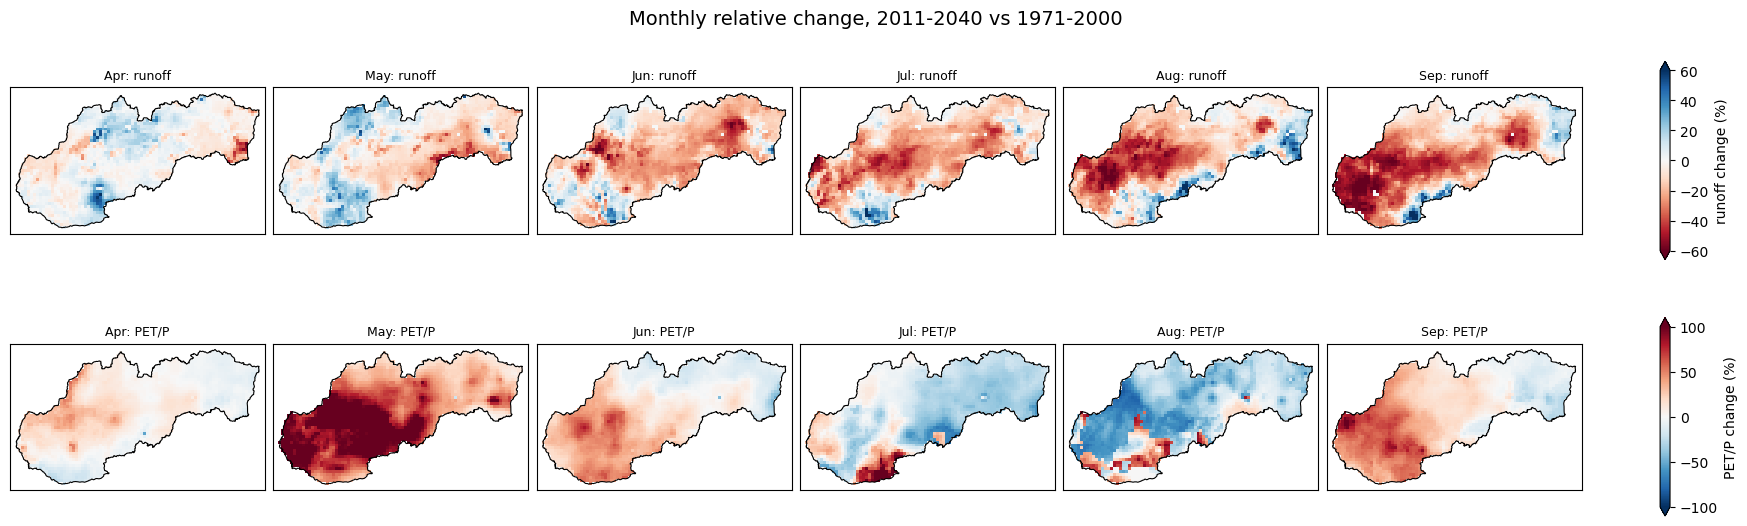

In [17]:
# Define the field of view for the chart
minx, miny, maxx, maxy = sk_poly.bounds
PAD = 10_000

def draw(ax, field, title, **kw):
    """One 2-D field in EPSG:3035 metres, shown only inside Slovakia, with the border on top."""
    m = ax.pcolormesh(Xw, Yw, np.where(inside, field, np.nan), shading="nearest", rasterized=True, **kw)
    boundary.boundary.plot(ax=ax, color="black", linewidth=0.8)
    ax.set_xlim(minx - PAD, maxx + PAD)
    ax.set_ylim(miny - PAD, maxy + PAD)
    ax.set_aspect("equal")                                              # No axis ticks
    ax.set_xticks([])                                                   # No axis ticks
    ax.set_yticks([])                                                   # No axis ticks
    ax.set_xlabel("")                                                   # Clearing geopanas default axis labels
    ax.set_ylabel("")                                                   # Clearing geopanas default axis labels
    ax.set_title(title, fontsize=9)
    return m

n_m = len(season_idx)
fig, axes = plt.subplots(2, n_m, figsize=(2.9 * n_m, 5.4), constrained_layout=True)
norm_run, norm_arid = TwoSlopeNorm(vmin=-60, vcenter=0, vmax=60), TwoSlopeNorm(vmin=-100, vcenter=0, vmax=100)
for j, k in enumerate(season_idx):
    label = calendar.month_abbr[int(months_run[k])]
    m_r = draw(axes[0, j], run_w.isel(time=k).values, f"{label}: runoff", cmap="RdBu", norm=norm_run)
    m_a = draw(axes[1, j], arid_w.isel(time=k).values, f"{label}: PET/P", cmap="RdBu_r", norm=norm_arid)
fig.colorbar(m_r, ax=axes[0, :], shrink=0.8, extend="both", label="runoff change (%)")
fig.colorbar(m_a, ax=axes[1, :], shrink=0.8, extend="both", label="PET/P change (%)")
fig.suptitle("Monthly relative change, 2011-2040 vs 1971-2000", fontsize=14)
plt.show()

**Visualizing the mean of the entire growing season, 2011-2040** 

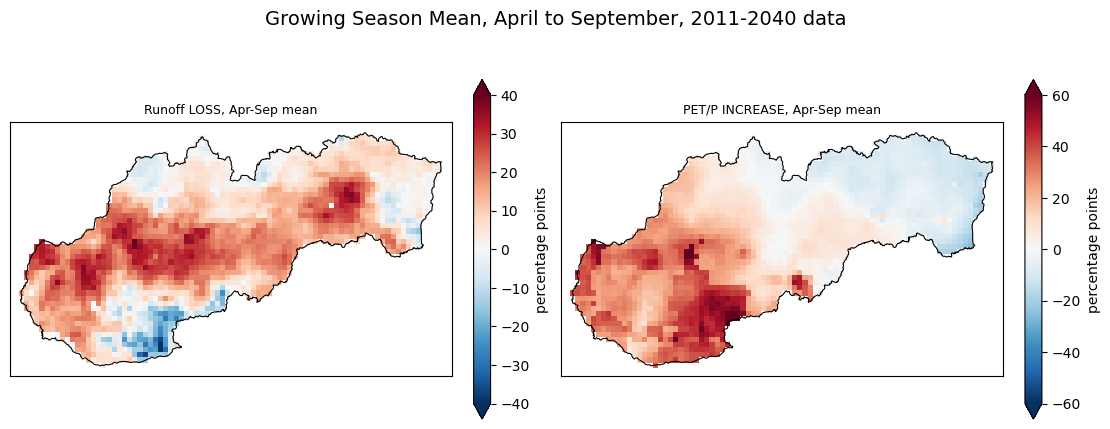

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), constrained_layout=True)
m1 = draw(axes[0], runoff_loss_pct.values, "Runoff LOSS, Apr-Sep mean", cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-40, vcenter=0, vmax=40))
m2 = draw(axes[1], aridity_chg_mean.values, "PET/P INCREASE, Apr-Sep mean", cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-60, vcenter=0, vmax=60))
fig.colorbar(m1, ax=axes[0], shrink=0.8, extend="both", label="percentage points")
fig.colorbar(m2, ax=axes[1], shrink=0.8, extend="both", label="percentage points")
fig.suptitle("Growing Season Mean, April to September, 2011-2040", fontsize=14)

plt.show()

**Map of the 5 classes of the water stress indicator**

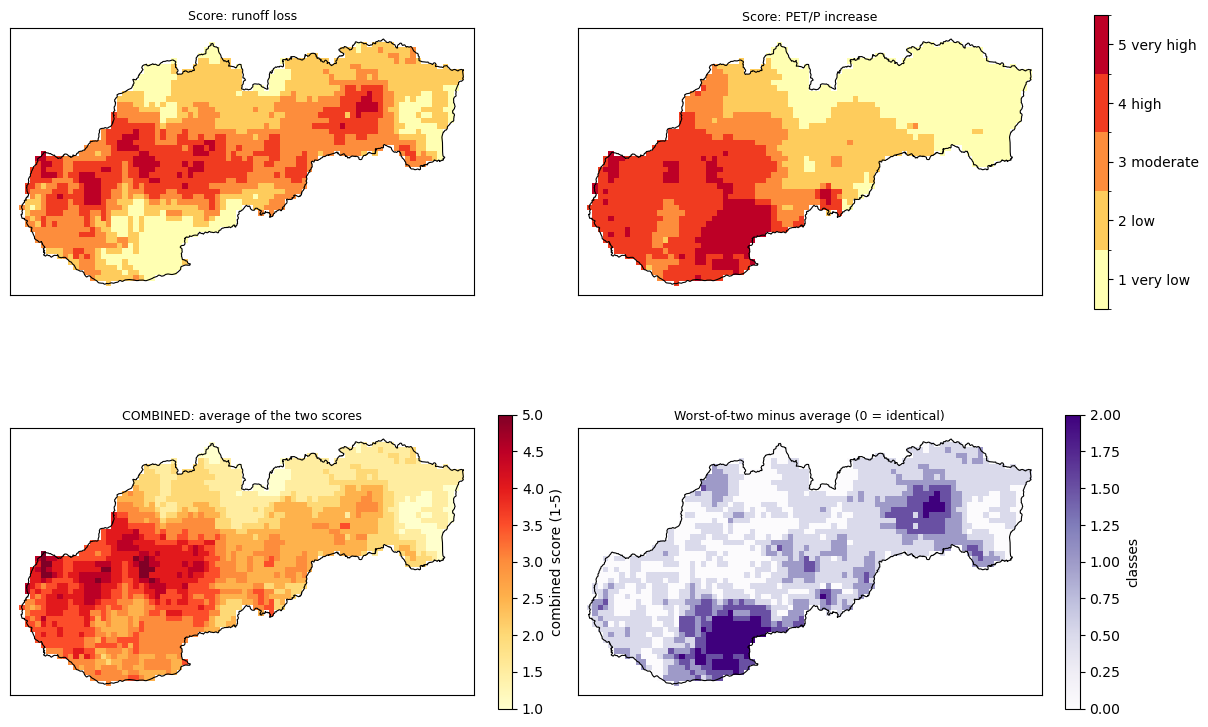

In [ ]:
class_cmap = ListedColormap(["#ffffb2", "#fecc5c", "#fd8d3c", "#f03b20", "#bd0026"])
class_norm = BoundaryNorm(np.arange(0.5, 6.5, 1.0), class_cmap.N)

fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
mA = draw(axes[0, 0], score_runoff, "Score: runoff loss", cmap=class_cmap, norm=class_norm)
mB = draw(axes[0, 1], score_arid, "Score: PET/P increase", cmap=class_cmap, norm=class_norm)
mC = draw(axes[1, 0], score_mean, "Average of the two scores", cmap="YlOrRd", vmin=1, vmax=5)
mD = draw(axes[1, 1], score_worst - score_mean, "Worst-of-two minus average (0 = scores identical)", cmap="Purples", vmin=0, vmax=2)
cb = fig.colorbar(mA, ax=axes[0, :], ticks=[1, 2, 3, 4, 5], shrink=0.75)
cb.ax.set_yticklabels([f"{c} {CLASS_NAMES[c]}" for c in range(1, 6)])
fig.colorbar(mC, ax=axes[1, 0], shrink=0.75, label="combined score (1-5)")
fig.colorbar(mD, ax=axes[1, 1], shrink=0.75, label="classes")
plt.show()